# Lab 3 — Forecasting baselines and causal temporal features

**Audience:** beginner Strategic Engineering MSc students  
**Scope:** Lecture 3, **slides 1–68 only**  
**Estimated lab time:** 80–90 minutes

## Engineering problem
You are supporting the energy manager of an industrial facility. Every hour, you must forecast the facility's **electricity demand for the next hour**.

A useful forecasting method should not merely have a low error: it should beat credible simple alternatives under the **same chronological evaluation protocol**.

## Learning objectives
By the end of the lab you should be able to:

1. implement constant, persistence, drift, seasonal-naïve, moving-average, and exponential-smoothing baselines;
2. compare methods with MAE and RMSE using a chronological train/validation/test split;
3. transform a time series into a causal tabular feature set using lags, differences, rolling statistics, and contextual variables;
4. fit a simple linear forecasting model on those features;
5. explain what a strong baseline tells you about the structure of the forecasting problem;
6. detect and avoid **future-information leakage** in feature construction.

> **Prediction-time rule:** to predict demand at hour *t*, every signal-derived input must come from times earlier than *t*. A contextual variable may refer to *t* only if it is genuinely known in advance (for example, a production plan).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

np.random.seed(7)
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Inspect the engineering data

In [2]:
# Synthetic but realistic hourly facility data: no download is required.
N_DAYS = 120
N = 24 * N_DAYS
t = np.arange(N)
time = pd.date_range("2026-01-01", periods=N, freq="h")
hour = time.hour.to_numpy()
dow = time.dayofweek.to_numpy()
weekday = (dow < 5).astype(float)

# Ambient temperature with daily + slow variation.
temperature = (
    17
    + 6 * np.sin(2*np.pi*(hour - 8)/24)
    + 2.5 * np.sin(2*np.pi*t/(24*30))
    + np.random.normal(0, 0.8, N)
)

# Planned production intensity: known in advance from the schedule.
working_hours = ((hour >= 7) & (hour <= 18)).astype(float)
production_plan = weekday * (0.35 + 0.65 * working_hours)

# Electricity demand. Temperature affects demand with about a 2-hour delay.
temp_lag2 = np.r_[temperature[:2], temperature[:-2]]
daily = 7 * np.sin(2*np.pi*(hour - 6)/24) + 3*np.cos(4*np.pi*hour/24)
weekly = 3 * np.sin(2*np.pi*t/(24*7))
slow_drift = 0.004 * t
noise = np.random.normal(0, 2.2, N)

demand = (
    72
    + 24 * production_plan
    + 0.55 * temp_lag2
    + daily
    + weekly
    + slow_drift
    + noise
)

df = pd.DataFrame({
    "demand": demand,
    "temperature": temperature,
    "production_plan": production_plan,
}, index=time)

df.head()

,demand,temperature,production_plan
2026-01-01 00:00:00,88.320249,13.156268,0.35
2026-01-01 01:00:00,83.971770,10.853511,0.35
2026-01-01 02:00:00,81.648629,11.069887,0.35
2026-01-01 03:00:00,82.483209,11.595900,0.35
2026-01-01 04:00:00,75.554378,11.259958,0.35


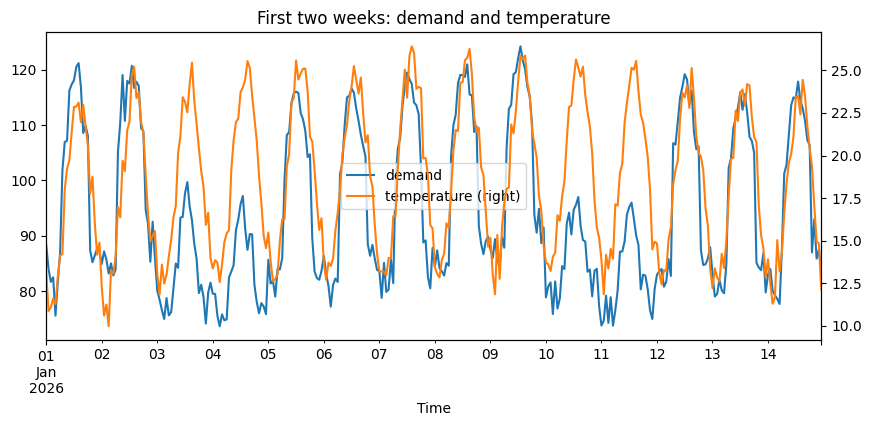

In [3]:
ax = df.iloc[:24*14][["demand", "temperature"]].plot(secondary_y="temperature")
ax.set_title("First two weeks: demand and temperature")
ax.set_xlabel("Time")
plt.show()

### Before coding
The target of row *t* is `demand[t]`. Imagine that the forecast is issued just before hour *t* begins.

Classify each candidate input as **available** or **not available** at that moment:
- `demand[t]`
- `demand[t-1]`
- `temperature[t-1]`
- planned production for hour `t`

The key question is always operational: *would this information exist at prediction time?*

**Suggested answer:** `demand[t]` is not available; the other three are available under the stated assumptions.

## 2. Chronological split and common metrics

In [4]:
# Chronological split: first 60% train, next 20% validation, last 20% test.
n = len(df)
i_train = int(0.60 * n)
i_val = int(0.80 * n)

train = df.iloc[:i_train].copy()
val = df.iloc[i_train:i_val].copy()
test = df.iloc[i_val:].copy()

print(train.index.min(), "→", train.index.max(), len(train))
print(val.index.min(),   "→", val.index.max(),   len(val))
print(test.index.min(),  "→", test.index.max(),  len(test))

2026-01-01 00:00:00 → 2026-03-13 23:00:00 1728
2026-03-14 00:00:00 → 2026-04-06 23:00:00 576
2026-04-07 00:00:00 → 2026-04-30 23:00:00 576


In [5]:
def metrics(y_true, y_pred):
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = np.asarray(y_true)[mask]
    y_pred = np.asarray(y_pred)[mask]
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
    }

def evaluate_period(data, pred_col):
    return metrics(data["demand"].to_numpy(), data[pred_col].to_numpy())

## 3. Baseline ladder: constant, persistence, drift, seasonal naïve

In [6]:
# Work on one full timeline so that validation/test forecasts may use genuinely
# available observations from immediately before the split boundary.
all_data = df.copy()

# 1) Constant baseline: fitted on TRAINING data only.
train_mean = train["demand"].mean()
all_data["pred_mean"] = train_mean

# 2) Persistence: forecast y[t] with y[t-1].
all_data["pred_persistence"] = all_data["demand"].shift(1)

# 3) Drift: extrapolate the most recent one-step change.
all_data["pred_drift"] = 2*all_data["demand"].shift(1) - all_data["demand"].shift(2)

# 4) Daily seasonal naive: same hour one day earlier.
all_data["pred_seasonal24"] = all_data["demand"].shift(24)

# Re-create chronological views with prediction columns.
train_b = all_data.iloc[:i_train].copy()
val_b   = all_data.iloc[i_train:i_val].copy()
test_b  = all_data.iloc[i_val:].copy()

rows = []
for name in ["pred_mean", "pred_persistence", "pred_drift", "pred_seasonal24"]:
    m = evaluate_period(val_b, name)
    rows.append({"method": name.replace("pred_", ""), **m})

pd.DataFrame(rows).sort_values("MAE")

,method,MAE,RMSE
1,persistence,4.001663,5.804702
2,drift,5.970992,7.969885
3,seasonal24,7.042944,10.592199
0,mean,11.994492,14.710565


### Think
Which baseline is strongest on validation? What temporal assumption does each baseline encode?

- constant → target distribution only
- persistence → short-term continuity
- drift → recent local trend continues
- seasonal naïve → known repeating cycle

## 4. Moving-average baseline: select the window on validation

In [7]:
# Moving-average window length is a model-selection choice.
window_candidates = [3, 6, 12, 24, 48]
ma_results = []

for L in window_candidates:
    col = f"pred_ma_{L}"
    # shift(1): exclude the target y[t] itself; use only history through t-1.
    all_data[col] = all_data["demand"].shift(1).rolling(L).mean()
    val_tmp = all_data.iloc[i_train:i_val]
    m = evaluate_period(val_tmp, col)
    ma_results.append({"window": L, **m})

ma_results = pd.DataFrame(ma_results).sort_values("MAE")
ma_results

,window,MAE,RMSE
0,3,5.715301,7.804249
1,6,8.732364,11.178987
3,24,11.828612,13.663001
4,48,12.609210,14.517849
2,12,13.294239,15.621856


## 5. Exponential smoothing: select α on validation

In [8]:
# Exponential smoothing: choose alpha on validation data.
alpha_candidates = [0.05, 0.10, 0.20, 0.40, 0.70, 0.90]
es_results = []

for alpha in alpha_candidates:
    col = f"pred_es_{alpha}"
    # Smoothed level through t-1 becomes the forecast for t.
    all_data[col] = all_data["demand"].ewm(alpha=alpha, adjust=False).mean().shift(1)
    val_tmp = all_data.iloc[i_train:i_val]
    m = evaluate_period(val_tmp, col)
    es_results.append({"alpha": alpha, **m})

es_results = pd.DataFrame(es_results).sort_values("MAE")
es_results

,alpha,MAE,RMSE
5,0.90,4.063478,5.881034
4,0.70,4.491498,6.333451
3,0.40,6.266875,8.266909
2,0.20,9.115172,11.118297
1,0.10,11.084226,12.821950
0,0.05,12.050130,13.661153


Recall the recursion:

**x̂ₜ₊₁ = αxₜ + (1 − α)x̂ₜ**

A larger α reacts faster to recent observations; a smaller α produces a smoother, slower estimate.

## 6. Use autocorrelation as a diagnostic probe

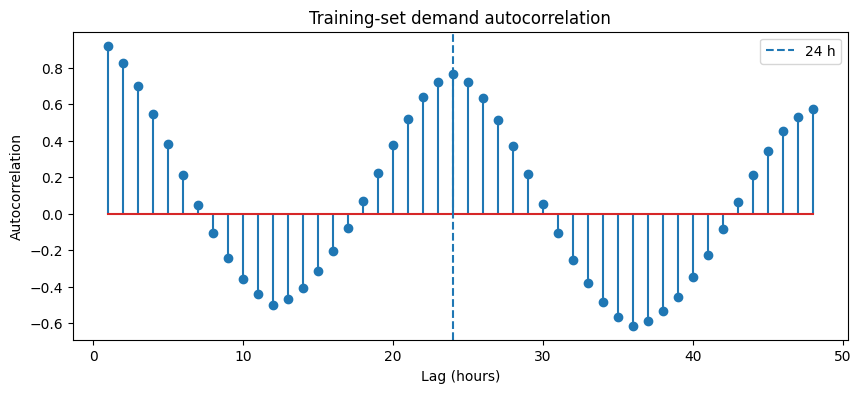

lag 1 : 0.922
lag 24: 0.769


In [9]:
# Autocorrelation is a descriptive probe of repeated temporal structure.
lags = np.arange(1, 49)
acf = [train["demand"].autocorr(lag=int(k)) for k in lags]

plt.stem(lags, acf)
plt.axvline(24, linestyle="--", label="24 h")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.title("Training-set demand autocorrelation")
plt.legend()
plt.show()

print("lag 1 :", round(train["demand"].autocorr(lag=1), 3))
print("lag 24:", round(train["demand"].autocorr(lag=24), 3))

Look especially at lags near **1 hour** and **24 hours**. A peak at lag 24 is consistent with daily repetition, but autocorrelation is descriptive: it does not establish a causal mechanism.

## 7. Optional: delayed relationship between variables

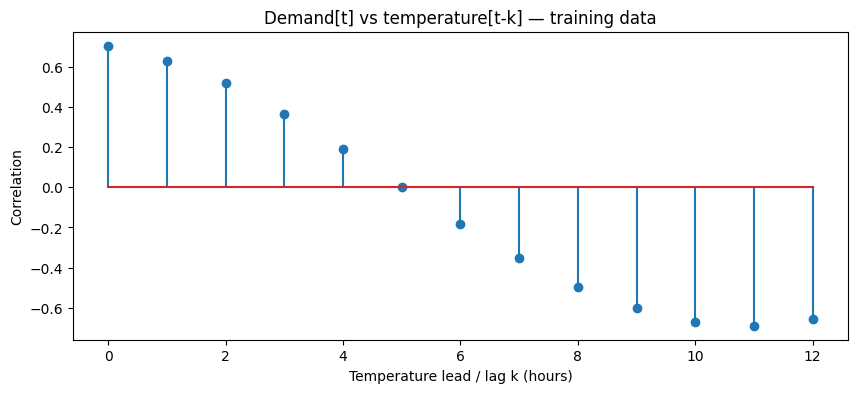

Strongest absolute correlation at lag 0


In [10]:
# Cross-correlation probe: does earlier temperature relate to current demand?
# lag k means correlate demand[t] with temperature[t-k].
xcorr_lags = np.arange(0, 13)
xcorr = [train["demand"].corr(train["temperature"].shift(int(k))) for k in xcorr_lags]

plt.stem(xcorr_lags, xcorr)
plt.xlabel("Temperature lead / lag k (hours)")
plt.ylabel("Correlation")
plt.title("Demand[t] vs temperature[t-k] — training data")
plt.show()

best_k = int(xcorr_lags[np.nanargmax(np.abs(xcorr))])
print("Strongest absolute correlation at lag", best_k)

Cross-correlation can suggest a useful delay between two recorded variables, but common drivers can create correlation too. Treat it as a feature-design clue, not as proof of causality.

## 8. Build a causal temporal feature table

In [11]:
# Build a causal feature table for target demand[t].
feat = pd.DataFrame(index=df.index)
feat["target"] = df["demand"]

# Position-preserving lag features.
feat["lag1"] = df["demand"].shift(1)
feat["lag2"] = df["demand"].shift(2)
feat["lag24"] = df["demand"].shift(24)

# Change / trend features.
feat["diff1"] = df["demand"].shift(1) - df["demand"].shift(2)
feat["trend6"] = df["demand"].shift(1) - df["demand"].shift(6)

# Rolling summary features. shift(1) is essential for causality.
hist = df["demand"].shift(1)
feat["mean6"] = hist.rolling(6).mean()
feat["std24"] = hist.rolling(24).std()

# Cross-variable lag suggested by the training-only exploratory analysis.
feat["temp_lag2"] = df["temperature"].shift(2)

# Context known before the target hour starts.
feat["production_plan"] = df["production_plan"]

feat = feat.dropna()
feat.head()

,target,lag1,lag2,lag24,diff1,trend6,mean6,std24,temp_lag2,production_plan
2026-01-02 00:00:00,84.903814,87.155479,87.670559,88.320249,-0.515080,-20.912548,90.308758,15.274909,14.167311,0.35
2026-01-02 01:00:00,87.158595,84.903814,87.155479,83.971770,-2.251665,-2.441864,86.448055,15.390630,14.879037,0.35
2026-01-02 02:00:00,85.703682,87.158595,84.903814,81.648629,2.254782,1.955891,86.416875,15.273263,12.287318,0.35
2026-01-02 03:00:00,83.160667,85.703682,87.158595,82.483209,-1.454913,-0.706416,86.500371,15.098802,10.585001,0.35
2026-01-02 04:00:00,85.010460,83.160667,85.703682,75.554378,-2.543016,-4.509892,85.958799,15.067596,11.238195,0.35


The feature table mixes two strategies from the lecture:

- **preserve positions:** explicit lag features such as `lag1`, `lag24`;
- **summarize intervals:** rolling mean, standard deviation, and trend.

It also includes a contextual variable (`production_plan`) that is assumed known at prediction time.

## 9. Linear forecasting model over engineered features

In [12]:
feature_cols = [c for c in feat.columns if c != "target"]

# Split by timestamps so the feature table follows the same chronology.
train_f = feat.loc[feat.index < val.index.min()]
val_f   = feat.loc[(feat.index >= val.index.min()) & (feat.index < test.index.min())]
test_f  = feat.loc[feat.index >= test.index.min()]

model = LinearRegression()
model.fit(train_f[feature_cols], train_f["target"])

val_pred = model.predict(val_f[feature_cols])
test_pred = model.predict(test_f[feature_cols])

print("Feature model validation:", metrics(val_f["target"], val_pred))
print("Feature model test      :", metrics(test_f["target"], test_pred))

coef = pd.Series(model.coef_, index=feature_cols).sort_values(key=np.abs, ascending=False)
coef

Feature model validation: {'MAE': 3.2180379443010363, 'RMSE': 3.989517468949713}
Feature model test      : {'MAE': 3.6813306197540845, 'RMSE': 4.446336463788972}


production_plan    16.290064
temp_lag2           0.236028
lag24               0.229114
lag1                0.219705
lag2                0.164556
std24              -0.160767
mean6              -0.086251
trend6              0.075609
diff1               0.055149
dtype: float64

### Teacher note
This is intentionally not a complex model. The pedagogical question is whether manually designed causal features add useful information beyond the strongest simple temporal baseline.

## 10. Freeze choices and compare once on the test set

In [13]:
# Freeze choices from validation, then evaluate once on test.
best_ma_L = int(ma_results.iloc[0]["window"])
best_alpha = float(es_results.iloc[0]["alpha"])

final_rows = []
for label, col in [
    ("constant mean", "pred_mean"),
    ("persistence", "pred_persistence"),
    ("drift", "pred_drift"),
    ("seasonal naive 24h", "pred_seasonal24"),
    (f"moving average L={best_ma_L}", f"pred_ma_{best_ma_L}"),
    (f"exp smoothing alpha={best_alpha}", f"pred_es_{best_alpha}"),
]:
    m = evaluate_period(all_data.iloc[i_val:], col)
    final_rows.append({"method": label, **m})

final_rows.append({"method":"linear engineered features", **metrics(test_f["target"], test_pred)})
results_test = pd.DataFrame(final_rows).sort_values("MAE")
results_test

,method,MAE,RMSE
6,linear engineered features,3.681331,4.446336
1,persistence,3.897018,5.840818
5,exp smoothing alpha=0.9,3.971033,5.930827
4,moving average L=3,5.663350,7.925003
2,drift,5.850632,7.917743
3,seasonal naive 24h,5.896626,9.209497
0,constant mean,12.182958,15.857834


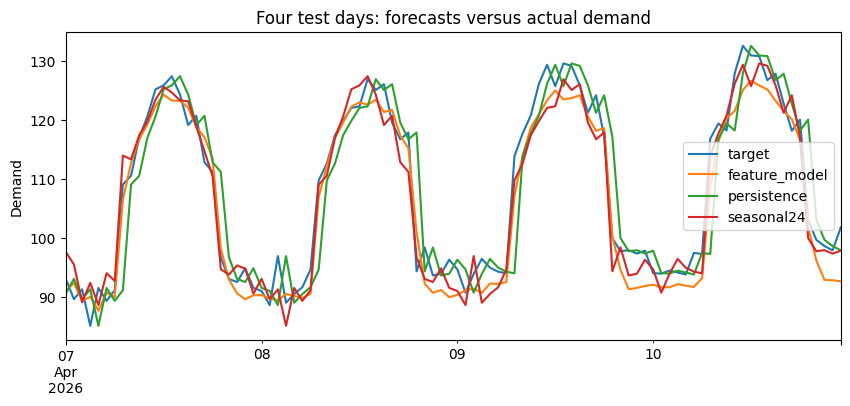

In [14]:
# Visual check on a short test interval.
show = test_f.iloc[:24*4].copy()
show["feature_model"] = test_pred[:len(show)]
show["persistence"] = all_data.loc[show.index, "pred_persistence"]
show["seasonal24"] = all_data.loc[show.index, "pred_seasonal24"]

show[["target", "feature_model", "persistence", "seasonal24"]].plot()
plt.title("Four test days: forecasts versus actual demand")
plt.ylabel("Demand")
plt.show()

## Interpretation — suggested answers

1. **Why is persistence often strong?**  
   Hourly demand is autocorrelated: the most recent level contains substantial information about the next hour.

2. **What does a strong 24-hour seasonal-naïve baseline tell us?**  
   The process contains a repeating daily structure. An advanced model should not receive credit merely for rediscovering it.

3. **Why must moving-average features use `shift(1)` before `rolling(...)`?**  
   The target at time *t* must not enter the feature used to predict itself. Without the shift, the rolling window includes future/unavailable information relative to the decision point.

4. **Why can `production_plan[t]` be allowed while `demand[t]` cannot?**  
   The production plan is assumed known before hour *t* starts; actual demand at *t* is the unknown target.

5. **What is the main lesson if the feature model improves only slightly over seasonal naïve?**  
   The extra complexity may have limited operational value. Complexity should be justified by a reliable improvement over the strongest credible simple method.

6. **What is the main limitation of this engineered representation?**  
   We manually chose lags, windows, statistics and contextual variables. Useful information not captured by those design choices can be lost.

## Take-away
A forecasting model is useful only relative to a meaningful reference.

The workflow used here is deliberately simple:

**chronological split → credible baselines → validation-based choices → causal features → simple learned model → final test comparison**

This is a strong foundation before moving to more complex temporal models.